# TP 1 - Vecteurs et espaces vectoriels
**Étudiant :** KHOMENKO Maxim

**Numéro du TP :** 1

**Date :** 09 Novembre 2026

**Version Python :** 3.13.5

**Bibliothèques utilisées :** numpy, matplotlib

In [37]:
import numpy as np
import matplotlib.pyplot as plt

## Exercice 1.1 : Construction et opérations élémentaires

### a) Créez les vecteurs suivants avec NumPy : $x = (1, -2, 3, 0, 5)^\top$ et $y = (2, 1, -1, 4, -3)^\top$.

In [38]:
# Exercice 1
x = np.array([1, -2, 3, 0, 5], dtype=float)
y = np.array([2, 1, -1, 4, -3], dtype=float)

### b) Calculez $3x - 2y$ et vérifiez le résultat à la main pour les deux premières composantes.

**Vérification des deux premières composantes à la main :**
* Composante 1 : $3(1) - 2(2) = 3 - 4 = -1$

* Composante 2 : $3(-2) - 2(1) = -6 - 2 = -8$

In [39]:
# b) combinaison lineaire
z = 3* x - 2* y
print("3x - 2y = ", z)

3x - 2y =  [-1. -8. 11. -8. 21.]


**Résultat :** NumPy renvoie $3x - 2y = (-1, -8, 11, -8, 21)^\top$. Les deux premières composantes, $-1$ et $-8$, correspondent exactement à celles calculées à la main. Les opérations s'appliquent composante par composante, sans boucle explicite.

### c) Calculez le produit scalaire $\langle x, y \rangle$ de deux façons : boucle Python explicite, puis `np.dot`. Comparez les résultats.

In [40]:
# c) produit scalaire
dot_boucle = sum(x[i] * y[i] for i in range(len(x)))
dot_numpy = np.dot(x, y)

print(f"<x, y> boucle = {dot_boucle}, numpy = {dot_numpy}")

<x, y> boucle = -18.0, numpy = -18.0


**Résultat :** Les deux méthodes renvoient le même résultat mathématique ($-18$). La boucle explicite applique la formule $\sum_{i=1}^n x_i y_i$ pas à pas. L'utilisation de `np.dot` permet d'obtenir ce résultat directement grâce à `numpy`.

### d) Les deux vecteurs sont-ils orthogonaux ? Justifiez.

Par définition, deux vecteurs sont orthogonaux si et seulement si leur produit scalaire est strictement nul (égal à zéro).
Ici, $\langle x, y \rangle = -18$. Les vecteurs $x$ et $y$ ne sont donc pas orthogonaux.

### Conclusion de l'exercice 1.1

J'ai appris à construire des vecteurs de $\mathbb{R}^5$ avec NumPy et à effectuer des opérations élémentaires sans boucle : $3x - 2y = (-1, -8, 11, -8, 21)^\top$, ce qui confirme ma vérification à la main. J'ai aussi appris que le produit scalaire $\langle x, y \rangle = -18$ donne le même résultat avec une boucle explicite et avec `np.dot`, mais que `np.dot` est plus concis. Comme ce produit scalaire est non nul, $x$ et $y$ ne sont pas orthogonaux.

## Exercice 1.2 : Normes et inégalités

### a) Calculez $\|x\|_1$, $\|x\|_2$ et $\|x\|_\infty$ pour le vecteur $x$ de l'exercice 1.

**Vérification à la main :**
* $\|x\|_1 = |1| + |-2| + |3| + |0| + |5| = 11$

* $\|x\|_2 = \sqrt{1 + 4 + 9 + 0 + 25} = \sqrt{39} \approx 6,245$

* $\|x\|_\infty = \max(|1|, |-2|, |3|, |0|, |5|) = 5$

In [41]:
# Exercice 2 --- normes
norm1 = np.linalg.norm(x, ord=1)
norm2 = np.linalg.norm(x, ord=2)
norminf = np.linalg.norm(x, ord=np.inf)

print(f"||x||_1 = {norm1:.4f}, ||x||_2 = {norm2:.4f}, ||x||_inf = {norminf:.4f}")

||x||_1 = 11.0000, ||x||_2 = 6.2450, ||x||_inf = 5.0000


**Résultat :** NumPy renvoie $\|x\|_1 = 11$, $\|x\|_2 \approx 6,2450$ et $\|x\|_\infty = 5$, ce qui correspond aux calculs à la main. Les trois normes donnent des valeurs différentes pour un même vecteur, car elles mesurent sa "taille" de façons différentes : $\|x\|_1$ additionne les valeurs absolues de toutes les composantes, $\|x\|_2 = \sqrt{\langle x, x \rangle}$ est liée au produit scalaire vu à l'exercice 1.1, et $\|x\|_\infty$ ne retient que la plus grande valeur absolue.

### b) Vérifiez numériquement l'inégalité de Cauchy-Schwarz : $|\langle x, y \rangle| \le \|x\|_2 \|y\|_2$.

On a $\langle x, y \rangle = -18$, $\|x\|_2 = \sqrt{39}$ et $\|y\|_2 = \sqrt{4 + 1 + 1 + 16 + 9} = \sqrt{31}$. Il faut donc vérifier que $18 \le \sqrt{39 \times 31} = \sqrt{1209}$.

In [42]:
norm2_y = np.linalg.norm(y, ord=2)

produit = abs(np.dot(x, y))
borne = norm2 * norm2_y

print(f"|<x, y>| = {produit:.4f}, ||x||_2 * ||y||_2 = {borne:.4f}")
print("Cauchy-Schwarz vérifiée :", produit <= borne)

|<x, y>| = 18.0000, ||x||_2 * ||y||_2 = 34.7707
Cauchy-Schwarz vérifiée : True


**Résultat :** $|\langle x, y \rangle| = 18$ est bien inférieur ou égal à $\|x\|_2 \|y\|_2 \approx 34,77$, donc l'inégalité de Cauchy-Schwarz est vérifiée pour ces deux vecteurs. La valeur absolue est nécessaire car le produit scalaire vaut $-18$, l'inégalité compare la valeur absolue du produit scalaire au produit des normes $L^2$.

### c) Vérifiez l'inégalité triangulaire : $\|x + y\|_2 \le \|x\|_2 + \|y\|_2$.

On a $x + y = (3, -1, 2, 4, 2)^\top$, donc $\|x + y\|_2 = \sqrt{9 + 1 + 4 + 16 + 4} = \sqrt{34}$. Il faut donc vérifier que $\sqrt{34} \le \sqrt{39} + \sqrt{31}$.

In [43]:
norm_somme = np.linalg.norm(x + y, ord=2)
somme_normes = norm2 + norm2_y

print(f"||x + y||_2 = {norm_somme:.4f}, ||x||_2 + ||y||_2 = {somme_normes:.4f}")
print("Inégalité triangulaire vérifiée :", norm_somme <= somme_normes)

||x + y||_2 = 5.8310, ||x||_2 + ||y||_2 = 11.8128
Inégalité triangulaire vérifiée : True


**Résultat :** $\|x + y\|_2 \approx 5,8310$ est inférieur à $\|x\|_2 + \|y\|_2 \approx 11,8128$, donc l'inégalité triangulaire est vérifiée pour ces deux vecteurs. La norme de la somme $x + y$, calculée composante par composante puis avec la définition de la norme $L^2$, est donc plus petite que la somme des normes.

### d) Construisez dix vecteurs aléatoires dans $\mathbb{R}^{100}$ et tracez un nuage de points comparant $\|\cdot\|_1$ et $\|\cdot\|_2$ pour chacun d'eux. Commentez la relation observée.

Rapports ||v||_1 / ||v||_2 : [8.25 8.02 7.62 8.2  7.92 8.04 8.   8.08 7.61 7.6 ]


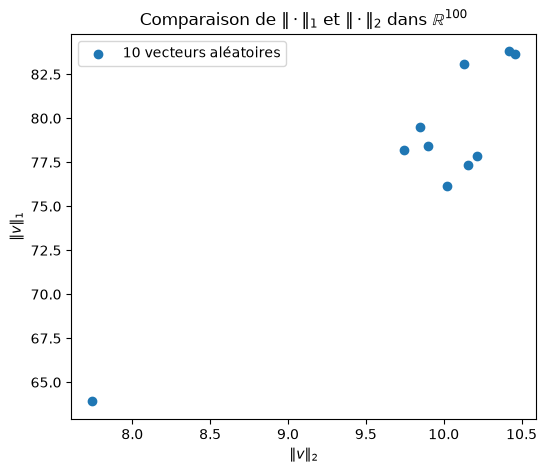

In [44]:
# Exercice 2 d --- Visualisation
rng = np.random.default_rng(42)
vecteurs = rng.standard_normal((10, 100))

normes_1 = np.linalg.norm(vecteurs, ord=1, axis=1)
normes_2 = np.linalg.norm(vecteurs, ord=2, axis=1)

print("Rapports ||v||_1 / ||v||_2 :", np.round(normes_1 / normes_2, 2))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(normes_2, normes_1, label="10 vecteurs aléatoires")
ax.set_xlabel(r"$\|v\|_2$")
ax.set_ylabel(r"$\|v\|_1$")
ax.set_title(r"Comparaison de $\|\cdot\|_1$ et $\|\cdot\|_2$ dans $\mathbb{R}^{100}$")
ax.legend()
plt.show()

**Commentaire :** le graphique montre neuf points regroupés et un point isolé en bas à gauche, qui a à la fois la plus petite norme $L^2$ et la plus petite norme $L^1$. À l'intérieur du groupe de neuf points, la relation entre les deux normes n'est pas nette, une norme $L^2$ plus grande ne correspond pas toujours à une norme $L^1$ plus grande. En revanche, le rapport $\|v\|_1 / \|v\|_2$ affiché reste presque constant, entre $7,60$ et $8,25$, pour ces dix vecteurs, $\|v\|_1$ vaut environ huit fois $\|v\|_2$. Ces deux normes mesurent chacune la taille d'un vecteur.

### Conclusion de l'exercice 1.2

J'ai appris à calculer les normes $L^1$, $L^2$ et $L^\infty$ d'un vecteur avec `np.linalg.norm` en changeant le paramètre `ord`, et à retrouver ces valeurs à la main à partir des définitions du cours. J'ai aussi appris à vérifier numériquement l'inégalité de Cauchy-Schwarz et l'inégalité triangulaire sur les vecteurs $x$ et $y$, elles sont toutes deux vérifiées pour cet exemple. Enfin, la comparaison de $\|\cdot\|_1$ et $\|\cdot\|_2$ sur dix vecteurs aléatoires de $\mathbb{R}^{100}$ m'a appris que le rapport $\|v\|_1 / \|v\|_2$ reste proche de 8 pour ces dix vecteurs, même si le nuage de points n'est pas parfaitement aligné.

## Exercice 1.3 : Indépendance linéaire et bases dans $\mathbb{R}^2$

### a) Soient $v_1 = (1, 2)^\top$, $v_2 = (-1, 1)^\top$, $v_3 = (2, 4)^\top$. Déterminez par calcul lequel de ces vecteurs est combinaison linéaire des autres.

**Calcul :**
* Cherchons $a, b$ tels que $v_3 = a v_1 + b v_2$. Composante par composante : $a - b = 2$ et $2a + b = 4$. En additionnant les deux équations : $3a = 6$, donc $a = 2$, puis $b = 0$. Ainsi $v_3 = 2v_1$.

* Réciproquement, $v_1 = \tfrac{1}{2}v_3$.

* $v_2$ n'est pas combinaison linéaire de $v_1$ et $v_3$ : toute combinaison $av_1+bv_3=(a+2b)(1,2)^\top$ a sa seconde composante égale au double de la première, alors que pour $v_2=(-1,1)^\top$ on a $1\neq 2\times(-1)$.

* Enfin, $\alpha v_1 + \beta v_2 = 0$ donne $\alpha - \beta = 0$ et $2\alpha + \beta = 0$, donc $\alpha = \beta = 0$ : $v_1$ et $v_2$ sont linéairement indépendants.

In [45]:
v1 = np.array([1., 2.])
v2 = np.array([-1., 1.])
v3 = np.array([2., 4.])

# v3 est-il egal a 2*v1 ?
print("2*v1 - v3 =", 2*v1 - v3)

# v2 : seconde composante comparee au double de la premiere
print("Seconde composante de v2 :", v2[1], "; double de la première :", 2*v2[0])

2*v1 - v3 = [0. 0.]
Seconde composante de v2 : 1.0 ; double de la première : -2.0


**Résultat :** $2v_1 - v_3 = (0, 0)^\top$, donc $v_3 = 2v_1$ : $v_3$ est combinaison linéaire de $v_1$ (et, réciproquement, $v_1 = \tfrac12 v_3$). D'après le calcul, $v_2$ n'est pas combinaison linéaire de $v_1$ et $v_3$, toute combinaison de $v_1$ et $v_3$ a sa seconde composante égale au double de la première, alors que pour $v_2$ on a $1 \neq 2 \times (-1)$.

### b) Construisez une base orthonormée de $\mathbb{R}^2$ en appliquant manuellement le procédé de Gram-Schmidt à $v_1$ et $v_2$ :

**Calcul à la main :**

- Calcul de $u_1$ :
$$
u_1=\frac{v_1}{\|v_1\|_2}
=\frac{(1,2)^\top}{\sqrt{1^2+2^2}}
=\frac{(1,2)^\top}{\sqrt5}
\approx (0,4472;\ 0,8944)^\top
$$

- Calcul du produit scalaire :
$$
\begin{aligned}
\langle v_2,u_1\rangle
&=(-1)(0,4472)+(1)(0,8944)\\
&\approx 0,4472
\end{aligned}
$$

- Calcul de la projection :
$$
\begin{aligned}
\langle v_2,u_1\rangle u_1
&=0,4472(0,4472;\ 0,8944)^\top\\
&\approx (0,2;\ 0,4)^\top
\end{aligned}
$$

- Calcul du vecteur intermédiaire :
$$
\begin{aligned}
w&=v_2-\langle v_2,u_1\rangle u_1\\
&=(-1;\ 1)^\top-(0,2;\ 0,4)^\top\\
&=(-1,2;\ 0,6)^\top
\end{aligned}
$$

- Calcul de la norme de $w$ :
$$
\begin{aligned}
\|w\|_2
&=\sqrt{(-1,2)^2+(0,6)^2}\\
&=\sqrt{1,8}\\
&\approx 1,3416
\end{aligned}
$$

- Calcul de $u_2$ :
$$
\begin{aligned}
u_2&=\frac{w}{\|w\|_2}\\
&=\frac{(-1,2;\ 0,6)^\top}{1,3416}\\
&\approx (-0,8944;\ 0,4472)^\top
\end{aligned}
$$

In [46]:
# Gram-Schmidt applique a v1 et v2
u1 = v1 / np.linalg.norm(v1, ord=2)

prod_v2_u1 = np.dot(v2, u1)
w = v2 - prod_v2_u1 * u1
u2 = w / np.linalg.norm(w, ord=2)

print("<v2, u1> =", prod_v2_u1)
print("w =", w)
print("u1 =", u1)
print("u2 =", u2)

<v2, u1> = 0.4472135954999579
w = [-1.2  0.6]
u1 = [0.4472136  0.89442719]
u2 = [-0.89442719  0.4472136 ]


**Résultat :** le code redonne les valeurs du calcul à la main : $\langle v_2, u_1 \rangle \approx 0,4472$, $w = (-1,2;\ 0,6)^\top$, $u_1 \approx (0,4472;\ 0,8944)^\top$ et $u_2 \approx (-0,8944;\ 0,4472)^\top$. Les formules de l'énoncé sont appliquées pas à pas avec le produit scalaire et la norme $L^2$ du cours.

### c) Vérifiez que $\langle u_1, u_2 \rangle = 0$ et $\|u_i\|_2 = 1$.

**Vérification à la main :**

- Vérification de l'orthogonalité :
$$
\langle u_1, u_2 \rangle
= \frac{1}{5}((1)(-2) + (2)(1))
= \frac{-2+2}{5}
= 0.
$$

- Vérification des normes :
$$
\|u_1\|_2^2 = \frac{1+4}{5} = 1
\Rightarrow \|u_1\|_2 = 1.
$$

$$
\|u_2\|_2^2 = \frac{4+1}{5} = 1
\Rightarrow \|u_2\|_2 = 1.
$$

In [47]:
print(f"<u1, u2> = {np.dot(u1, u2):.4f}")
print(f"||u1||_2 = {np.linalg.norm(u1, ord=2):.4f}, ||u2||_2 = {np.linalg.norm(u2, ord=2):.4f}")

<u1, u2> = 0.0000
||u1||_2 = 1.0000, ||u2||_2 = 1.0000


**Résultat :** le code affiche $\langle u_1, u_2 \rangle = 0,0000$ et $\|u_1\|_2 = \|u_2\|_2 = 1,0000$, ce qui correspond au calcul à la main : $\langle u_1, u_2 \rangle = 0$ et $\|u_1\|_2 = \|u_2\|_2 = 1$. D'après les définitions du rappel de cours, $\{u_1, u_2\}$ est donc orthonormal. À titre de comparaison, $\langle v_1, v_2 \rangle = (1)(-1) + (2)(1) = 1 \neq 0$ : $v_1$ et $v_2$ ne sont pas orthogonaux.

### d) Visualisez dans $\mathbb{R}^2$ : la base canonique $\{e_1, e_2\}$, les vecteurs $v_1, v_2$ et la base $\{u_1, u_2\}$. Utilisez `plt.quiver` avec des couleurs distinctes et une légende.

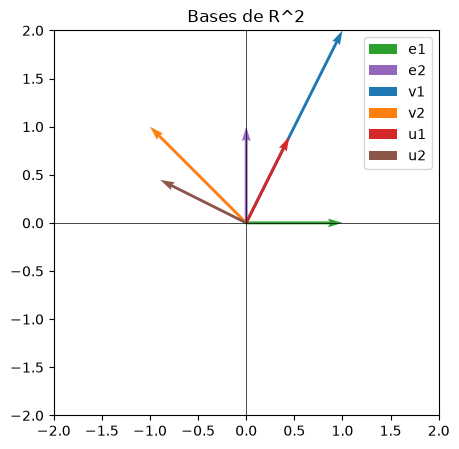

In [48]:
e1 = np.array([1., 0.])
e2 = np.array([0., 1.])

fig, ax = plt.subplots(figsize=(5, 5))
origin = [0, 0]
opts = dict(angles='xy', scale_units='xy', scale=1)   # fleches a leur vraie longueur

ax.quiver(*origin, *e1, color='tab:green', label='e1', **opts)
ax.quiver(*origin, *e2, color='tab:purple', label='e2', **opts)
ax.quiver(*origin, *v1, color='tab:blue', label='v1', **opts)
ax.quiver(*origin, *v2, color='tab:orange', label='v2', **opts)
ax.quiver(*origin, *u1, color='tab:red', label='u1', **opts)
ax.quiver(*origin, *u2, color='tab:brown', label='u2', **opts)

ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
ax.set_aspect('equal')
ax.set_title("Bases de R^2")
ax.legend()
plt.show()

**Commentaire :**
- $e_1 = (1, 0)^\top$ et $e_2 = (0, 1)^\top$ forment la base canonique de $\mathbb{R}^2$. Le cours illustre cette construction dans $\mathbb{R}^3$ avec des vecteurs $e_i$ dont la $i$-ème coordonnée vaut $1$ et les autres $0$, le même principe s'applique dans $\mathbb{R}^2$. Ils sont orthonormaux : $\langle e_1, e_2 \rangle = (1)(0) + (0)(1) = 0$ et $\|e_1\|_2 = \|e_2\|_2 = 1$.

- $u_1 = \frac{1}{\sqrt5}v_1$ est un multiple scalaire de $v_1$, de norme $1$, alors que $\|v_1\|_2 = \sqrt5 \approx 2,24$. Sur le graphique, leurs flèches sont alignées et ont le même sens, mais celle de $u_1$ est plus courte.

- $\langle u_1, u_2 \rangle = 0$, sur le graphique, $u_1$ et $u_2$ apparaissent perpendiculaires, comme $e_1$ et $e_2$. En revanche, $\langle v_1, v_2 \rangle = 1 \neq 0$, donc $v_1$ et $v_2$ ne sont pas orthogonaux.

- $u_2 \approx (-0,89;\ 0,45)^\top$ n'est pas un multiple de $v_2 = (-1, 1)^\top$, les rapports des composantes correspondantes sont différents, car $\frac{-0,89}{-1} \approx 0,89$ tandis que $\frac{0,45}{1} \approx 0,45$.

### Conclusion de l'exercice 1.3

J'ai appris à déterminer par calcul si un vecteur est combinaison linéaire des autres, ici $v_3 = 2v_1$, donc la famille $\{v_1, v_2, v_3\}$ n'est pas linéairement indépendante, alors que $v_1$ et $v_2$ le sont. J'ai aussi appris à appliquer pas à pas les formules de Gram-Schmidt avec `np.dot` et `np.linalg.norm` pour obtenir $u_1 \approx (0,4472;\ 0,8944)^\top$ et $u_2 \approx (-0,8944;\ 0,4472)^\top$, puis à vérifier par le calcul que $\langle u_1, u_2 \rangle = 0$ et $\|u_i\|_2 = 1$, c'est-à-dire que $\{u_1, u_2\}$ est orthonormal. Enfin, j'ai appris à représenter des vecteurs de $\mathbb{R}^2$ avec `plt.quiver` et à constater sur le graphique que $u_1$ et $u_2$ sont perpendiculaires, contrairement à $v_1$ et $v_2$.

## Exercice 1.4 : Application - Similarité cosinus

### a) Calculez la similarité cosinus entre chaque paire parmi les trois vecteurs $x_1 = (3, 1, 0, 2)^\top$, $x_2 = (2, 0, 1, 1)^\top$, $x_3 = (-1, -2, 0, -3)^\top$.

**Calcul à la main :**

- Calcul des normes :
$$
\begin{aligned}
\|x_1\|_2 &= \sqrt{3^2+1^2+0^2+2^2} = \sqrt{14}\\
\|x_2\|_2 &= \sqrt{2^2+0^2+1^2+1^2} = \sqrt{6}\\
\|x_3\|_2 &= \sqrt{(-1)^2+(-2)^2+0^2+(-3)^2} = \sqrt{14}
\end{aligned}
$$

- Calcul des produits scalaires :
$$
\begin{aligned}
\langle x_1,x_2\rangle &= (3)(2)+(1)(0)+(0)(1)+(2)(1)=8\\
\langle x_1,x_3\rangle &= (3)(-1)+(1)(-2)+(0)(0)+(2)(-3)=-11\\
\langle x_2,x_3\rangle &= (2)(-1)+(0)(-2)+(1)(0)+(1)(-3)=-5
\end{aligned}
$$

- Application de la formule de similarité cosinus :

$$
\cos(x_1,x_2)
=\frac{8}{\sqrt{14}\times\sqrt{6}}
=\frac{8}{\sqrt{84}}
\approx 0,8729
$$

$$
\cos(x_1,x_3)
=\frac{-11}{\sqrt{14}\times\sqrt{14}}
=\frac{-11}{14}
\approx -0,7857
$$

$$
\cos(x_2,x_3)
=\frac{-5}{\sqrt{6}\times\sqrt{14}}
=\frac{-5}{\sqrt{84}}
\approx -0,5455
$$

In [49]:
x1 = np.array([3, 1, 0, 2], dtype=float)
x2 = np.array([2, 0, 1, 1], dtype=float)
x3 = np.array([-1, -2, 0, -3], dtype=float)

def cos_sim(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a, ord=2) * np.linalg.norm(b, ord=2)))

cos_12 = cos_sim(x1, x2)
cos_13 = cos_sim(x1, x3)
cos_23 = cos_sim(x2, x3)

print(f"cos(x1, x2) = {cos_12:.4f}")
print(f"cos(x1, x3) = {cos_13:.4f}")
print(f"cos(x2, x3) = {cos_23:.4f}")

cos(x1, x2) = 0.8729
cos(x1, x3) = -0.7857
cos(x2, x3) = -0.5455


**Résultat :** le code redonne les trois valeurs calculées à la main : $\cos(x_1, x_2) \approx 0,8729$, $\cos(x_1, x_3) \approx -0,7857$ et $\cos(x_2, x_3) \approx -0,5455$. Chaque valeur est le produit scalaire de deux vecteurs divisé par le produit de leurs normes $L^2$. Les deux dernières valeurs sont négatives, car les composantes de $x_1$ et $x_2$ sont positives ou nulles, tandis que celles de $x_3$ sont négatives ou nulles. Leurs produits scalaires avec $x_3$ sont donc négatifs.

### b) Quel est le couple de vecteurs le plus similaire ? le plus opposé ?

La similarité cosinus mesure la proximité de deux vecteurs. On lit les trois valeurs obtenues en a) :

- **Le plus similaire :** le couple $(x_1, x_2)$, dont la valeur $0,8729$ est la plus grande.
- **Le plus opposé :** le couple $(x_1, x_3)$, dont la valeur $-0,7857$ est la plus petite (la plus négative).

Le couple $(x_2, x_3)$, avec $-0,5455$, est également négatif, mais sa valeur est moins négative que celle de $(x_1, x_3)$.

### c) Que se passe-t-il si l'on normalise les vecteurs avant de calculer le produit scalaire ? Vérifiez numériquement.

Pour normaliser un vecteur, il faut le diviser par sa norme $L^2$ : $\hat{x} = x / \|x\|_2$.

Lorsqu'on calcule le produit scalaire de deux vecteurs normalisés, on obtient :

$$
\langle \hat{x}, \hat{y} \rangle
= \frac{\langle x,y\rangle}{\|x\|_2 \|y\|_2}
= \cos(\theta).
$$

Le produit scalaire des vecteurs normalisés est donc égal à leur similarité cosinus.

**Vérification numérique :**

On normalise les trois vecteurs, puis on calcule leurs produits scalaires avec NumPy pour vérifier que les résultats correspondent à ceux obtenus en a).

In [50]:
# Normalisation des vecteurs
x1_n = x1 / np.linalg.norm(x1, ord=2)
x2_n = x2 / np.linalg.norm(x2, ord=2)
x3_n = x3 / np.linalg.norm(x3, ord=2)

print(f"||x1_n||_2 = {np.linalg.norm(x1_n, ord=2):.4f}, ||x2_n||_2 = {np.linalg.norm(x2_n, ord=2):.4f}, ||x3_n||_2 = {np.linalg.norm(x3_n, ord=2):.4f}")
print(f"<x1_n, x2_n> = {np.dot(x1_n, x2_n):.4f}   (cos(x1, x2) = {cos_12:.4f})")
print(f"<x1_n, x3_n> = {np.dot(x1_n, x3_n):.4f}   (cos(x1, x3) = {cos_13:.4f})")
print(f"<x2_n, x3_n> = {np.dot(x2_n, x3_n):.4f}   (cos(x2, x3) = {cos_23:.4f})")

||x1_n||_2 = 1.0000, ||x2_n||_2 = 1.0000, ||x3_n||_2 = 1.0000
<x1_n, x2_n> = 0.8729   (cos(x1, x2) = 0.8729)
<x1_n, x3_n> = -0.7857   (cos(x1, x3) = -0.7857)
<x2_n, x3_n> = -0.5455   (cos(x2, x3) = -0.5455)


**Résultat :** une fois les vecteurs normalisés, leurs normes valent $1$ et leurs produits scalaires $0,8729$, $-0,7857$ et $-0,5455$ correspondent aux similarités cosinus calculées en a). Cela confirme numériquement le résultat précédent : le produit scalaire de deux vecteurs normalisés est égal à leur similarité cosinus, puisque leurs normes valent alors $1$.

Les vecteurs $\hat{x}_i$ vérifient donc la seconde condition de la définition d'un ensemble orthonormal du rappel de cours (norme égale à $1$). Cependant, ils ne forment pas un ensemble orthonormal, car leurs produits scalaires deux à deux ne sont pas nuls.

### Conclusion de l'exercice 1.4

J'ai appris à calculer la similarité cosinus à partir du produit scalaire et de la norme $L^2$ : pour les trois vecteurs, $\cos(x_1, x_2) \approx 0,8729$, $\cos(x_1, x_3) \approx -0,7857$ et $\cos(x_2, x_3) \approx -0,5455$. J'ai appris à en déduire que $(x_1, x_2)$ est le couple le plus similaire (valeur la plus grande) et $(x_1, x_3)$ le plus opposé (valeur la plus petite). J'ai enfin constaté que normaliser les vecteurs avant de calculer leur produit scalaire redonne la similarité cosinus, ce que j'ai expliqué mathématiquement puis vérifié numériquement.